In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from ipywidgets import interact
import ipywidgets as widgets
from IPython.display import display

In [ ]:
df = pd.read_csv('Crimes_-_2001_to_Present_20261101.csv')
# df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y %I:%M:%S %p').dt.date 
# above line conv to date timer
df['Date'] = df['Date'].str[:10]
#just conv to string, makes later analysis more difficult, will have to truncate again, or make new col 'month', based on the truncated value of the first col
display(df.head())
display(df.describe())
display(df.info())



,ID,Date,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,FBI Code,X Coordinate,Y Coordinate,Year,Latitude,Longitude
0,14368435,10/24/2026,042XX N MARINE DR,CRIMINAL TRESPASS,TO RESIDENCE,RESIDENCE,False,False,1915,19,46.0,26,1170986.0,1928779.0,2026,41.960047,-87.646762
1,14373382,10/24/2026,103XX S VERNON AVE,OTHER OFFENSE,TELEPHONE THREAT,RESIDENCE,False,False,512,5,9.0,08A,1181072.0,1836493.0,2026,41.706580,-87.612529
2,14368301,10/24/2026,085XX S CHAPPEL AVE,ASSAULT,AGGRAVATED - OTHER FIREARM,STREET,False,False,412,4,8.0,04A,1191334.0,1848657.0,2026,41.739717,-87.574557
3,14372254,10/24/2026,0000X N UNKNOWN AVE,CRIMINAL SEXUAL ASSAULT,NON-AGGRAVATED,OTHER (SPECIFY),False,False,6100,61,0.0,02,NaN,NaN,2026,NaN,NaN
4,14368588,10/24/2026,096XX S HOUSTON AVE,CRIMINAL DAMAGE,TO PROPERTY,RESIDENCE - GARAGE,False,False,431,4,10.0,14,1198192.0,1841661.0,2026,41.720351,-87.549665


,ID,Beat,District,Ward,X Coordinate,Y Coordinate,Year,Latitude,Longitude
count,9.517290e+05,951729.000000,951729.000000,951725.000000,9.438430e+05,9.438430e+05,951729.000000,943843.000000,943843.000000
mean,1.362126e+07,1158.118405,11.350725,23.064168,1.165477e+06,1.887359e+06,2024.372249,41.846492,-87.668236
std,7.484415e+05,733.238489,7.326161,13.972820,1.625345e+04,3.150957e+04,1.089697,0.086649,0.059181
min,2.727900e+04,111.000000,1.000000,0.000000,1.091242e+06,1.813897e+06,2023.000000,41.644590,-87.939733
25%,1.329174e+07,532.000000,5.000000,10.000000,1.154163e+06,1.860183e+06,2023.000000,41.771782,-87.709327
50%,1.364367e+07,1033.000000,10.000000,23.000000,1.167350e+06,1.893766e+06,2024.000000,41.864138,-87.660994
75%,1.400378e+07,1732.000000,17.000000,34.000000,1.176796e+06,1.910210e+06,2025.000000,41.909561,-87.626740
max,1.437570e+07,6100.000000,61.000000,50.000000,1.205119e+06,1.951517e+06,2026.000000,42.022559,-87.524529


<class 'pandas.DataFrame'>
RangeIndex: 951729 entries, 0 to 951728
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    951729 non-null  int64  
 1   Date                  951729 non-null  str    
 2   Block                 951729 non-null  str    
 3   Primary Type          951729 non-null  str    
 4   Description           951729 non-null  str    
 5   Location Description  946898 non-null  str    
 6   Arrest                951729 non-null  bool   
 7   Domestic              951729 non-null  bool   
 8   Beat                  951729 non-null  int64  
 9   District              951729 non-null  int64  
 10  Ward                  951725 non-null  float64
 11  FBI Code              951729 non-null  str    
 12  X Coordinate          943843 non-null  float64
 13  Y Coordinate          943843 non-null  float64
 14  Year                  951729 non-null  int64  
 15  Latitude   

None

In [22]:
#filter top categories
df['crimecol'] = df['Primary Type'].astype("category")
top_categories = df['Primary Type'].value_counts().nlargest(10).index
df.loc[~df['Primary Type'].isin(top_categories), "crimecol"] = "OTHER OFFENSE"
df.loc[df['Primary Type'].isin(top_categories), "crimecol"] = df['Primary Type']
display(df.head())
display(df.info())


,ID,Date,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,FBI Code,X Coordinate,Y Coordinate,Year,Latitude,Longitude,crimecol
0,14368435,10/24/2026,042XX N MARINE DR,CRIMINAL TRESPASS,TO RESIDENCE,RESIDENCE,False,False,1915,19,46.0,26,1170986.0,1928779.0,2026,41.960047,-87.646762,OTHER OFFENSE
1,14373382,10/24/2026,103XX S VERNON AVE,OTHER OFFENSE,TELEPHONE THREAT,RESIDENCE,False,False,512,5,9.0,08A,1181072.0,1836493.0,2026,41.706580,-87.612529,OTHER OFFENSE
2,14368301,10/24/2026,085XX S CHAPPEL AVE,ASSAULT,AGGRAVATED - OTHER FIREARM,STREET,False,False,412,4,8.0,04A,1191334.0,1848657.0,2026,41.739717,-87.574557,ASSAULT
3,14372254,10/24/2026,0000X N UNKNOWN AVE,CRIMINAL SEXUAL ASSAULT,NON-AGGRAVATED,OTHER (SPECIFY),False,False,6100,61,0.0,02,NaN,NaN,2026,NaN,NaN,OTHER OFFENSE
4,14368588,10/24/2026,096XX S HOUSTON AVE,CRIMINAL DAMAGE,TO PROPERTY,RESIDENCE - GARAGE,False,False,431,4,10.0,14,1198192.0,1841661.0,2026,41.720351,-87.549665,CRIMINAL DAMAGE


<class 'pandas.DataFrame'>
RangeIndex: 951729 entries, 0 to 951728
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   ID                    951729 non-null  int64   
 1   Date                  951729 non-null  str     
 2   Block                 951729 non-null  str     
 3   Primary Type          951729 non-null  str     
 4   Description           951729 non-null  str     
 5   Location Description  946898 non-null  str     
 6   Arrest                951729 non-null  bool    
 7   Domestic              951729 non-null  bool    
 8   Beat                  951729 non-null  int64   
 9   District              951729 non-null  int64   
 10  Ward                  951725 non-null  float64 
 11  FBI Code              951729 non-null  str     
 12  X Coordinate          943843 non-null  float64 
 13  Y Coordinate          943843 non-null  float64 
 14  Year                  951729 non-null  int64   

None

In [ ]:
#interactive pie chart
df2 = df.query("Year > 2025")
df2['Primary Type'].value_counts().plot.pie()
plt.show()

In [ ]:
@interact(year=[2023,2024,2025,2026])
def pieplotcrimes(year=2026):
    pietempdf = df.query("Year == @year")
    pietempdf['Primary Type'].value_counts().head(8).plot.pie(autopct='%1.2f%%')
#how to make this better?, could make more interactive idk


interactive(children=(Dropdown(description='year', index=3, options=(2023, 2024, 2025, 2026), value=2026), Out…

In [ ]:
@interact(year=[2023, 2024, 2025, 2026])
def alluvialplot(year=2026):
    alluvialtempdf = df.query("Year == @year").copy()
    alluvialtempdf['ArrestNum'] = alluvialtempdf['Arrest'].astype(int)
        #alluvialtempf = df[df['Year']==year]

    fig = px.parallel_categories(
        alluvialtempdf,
        dimensions=['crimecol', 'Arrest', 'Domestic'],
        color='ArrestNum',
        color_continuous_scale=['steelblue', 'crimson'],
        width=800, height=450,
    )
    fig.update_traces(line_shape='hspline')
    fig.update_layout(coloraxis_showscale=False)
    fig.show()

interactive(children=(Dropdown(description='year', index=3, options=(2023, 2024, 2025, 2026), value=2026), Out…

make everything interactive, pie chart first, then alluvial, and then the scatterplot, and idk wtf to do for the holiday, could do the distributoin of the crimes per month, like a corr matrix or something

Import interactive package

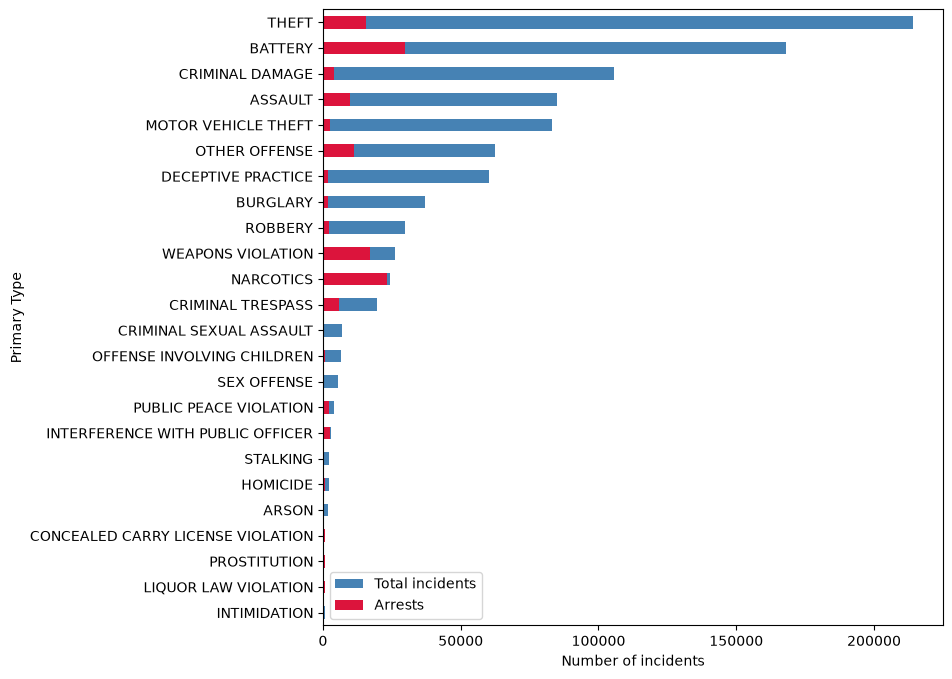

In [42]:
g = (df.groupby('Primary Type')['Arrest']
       .agg(total='size', arrests='sum')
       .query('total >= 500')
       .sort_values('total'))
g['total'].plot.barh(color='steelblue', figsize=(8, 8), label='Total incidents')
g['arrests'].plot.barh(color='crimson', label='Arrests')

plt.xlabel('Number of incidents')
plt.legend()
plt.show()

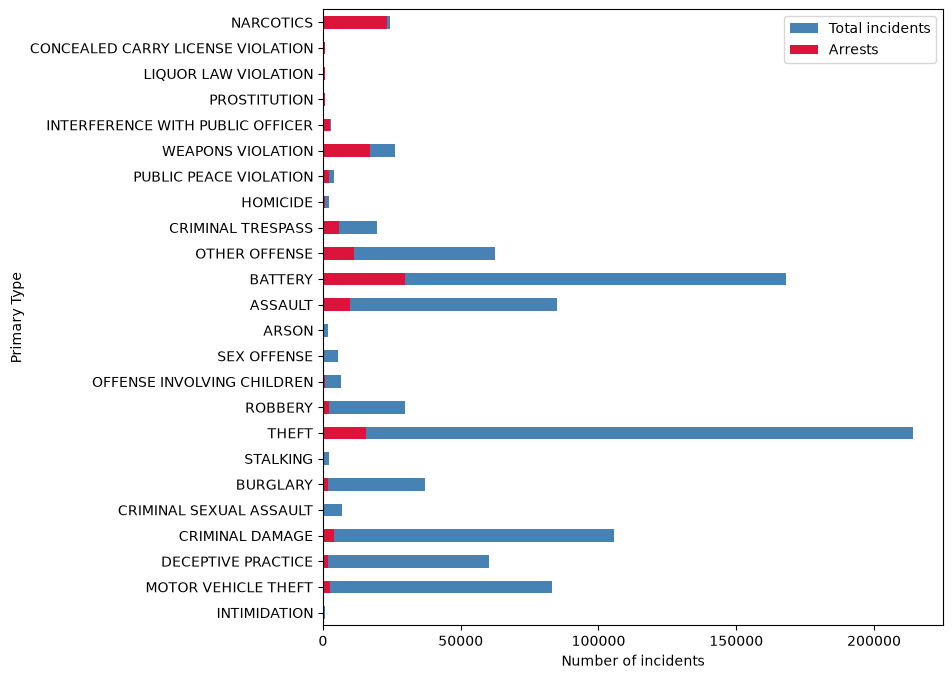

In [ ]:
g = (df.groupby('Primary Type')['Arrest']
       .agg(total='size', arrests='sum')
       .query('total >= 500')
)
#g = g.sort_values('total')
g['rate'] = g['arrests'] / g['total']
g = g.sort_values('rate')
g['total'].plot.barh(color='steelblue', figsize=(8, 8), label='Total incidents')
g['arrests'].plot.barh(color='crimson', label='Arrests')

plt.xlabel('Number of incidents')
plt.legend()
plt.show()